# Synthetic (avgdeg=15) HMRW Experiments

Runs resumable sweeps on synthetic Hy-MMSBM data:

`data/synthetic/hymmsbm/hy_mmsbm_avgdeg_15.pickle`

Sweeps: `p`, `q`, `r`, `num_walks`, `walk_length`, `dim`.

Evaluation: k-means (`k=3`) with ARI/NMI against known communities.


In [1]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

from hypergraphx import Hypergraph
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import normalize

from src.utils import hmrw_embeddings


In [2]:
def evaluate_embeddings(X, y, seed=42, n_clusters=3):
    km = KMeans(n_clusters=n_clusters, n_init=20, random_state=seed)
    Xn = normalize(X, norm="l2")
    pred = km.fit_predict(Xn)

    # Cluster labels are permutation-invariant; use ARI and NMI.
    ari = adjusted_rand_score(y, pred)
    nmi = normalized_mutual_info_score(y, pred)
    return float(ari), float(nmi)


In [3]:
data_path = Path("data") / "synthetic" / "hymmsbm" / "hy_mmsbm_avgdeg_15.pickle"
with open(data_path, "rb") as f:
    bundle = pickle.load(f)

edge_list = bundle["edge_list"]
y = np.asarray(bundle["labels"], dtype=int)
H = Hypergraph(edge_list)

print(f"Loaded: {data_path}")
print(f"nodes={len(H.get_nodes())}, edges={len(H.get_edges())}, labels={len(y)}")


Loaded: data/synthetic/hymmsbm/hy_mmsbm_avgdeg_15.pickle
nodes=100, edges=293, labels=100


In [4]:
results_dir = Path("results") / "synthetic" / "avgdeg15"
results_dir.mkdir(parents=True, exist_ok=True)

base_params = dict(
    p=1.0,
    q=1.0,
    r=1.0,
    num_walks=10,
    walk_length=40,
    window=10,
    dim=32,
    workers=1,
)

n_repeats = 5
base_seed = 42


In [5]:
# One-off run (no CSV saving)
one_params = dict(base_params)
one_params.update(
    p=2,
    q=2,
    r=1.0,
    num_walks=10,
    walk_length=40,
    dim=32,
)
one_seed = 42

X_one = hmrw_embeddings(H, seed=one_seed, **one_params)
ari_one, nmi_one = evaluate_embeddings(X_one, y, seed=one_seed)

print("one_params:", one_params)
print(f"ARI={ari_one:.4f}, NMI={nmi_one:.4f}")

one_params: {'p': 2, 'q': 2, 'r': 1.0, 'num_walks': 10, 'walk_length': 40, 'window': 10, 'dim': 32, 'workers': 1}
ARI=0.0456, NMI=0.0587


In [6]:
def run_resumable_sweep(varying_param, values, fixed_params, out_csv):
    out_csv = Path(out_csv)
    if out_csv.exists():
        df = pd.read_csv(out_csv)
    else:
        df = pd.DataFrame(columns=[
            varying_param,
            "ari_mean", "ari_std",
            "nmi_mean", "nmi_std",
            "n_repeats",
        ])

    done = set(df[varying_param].tolist()) if varying_param in df.columns else set()

    for val in values:
        if val in done:
            print(f"skip {varying_param}={val}")
            continue

        print(f"run {varying_param}={val}")
        ari_runs, nmi_runs = [], []
        for rep in range(n_repeats):
            seed = base_seed + rep
            params = dict(fixed_params)
            params[varying_param] = val
            X = hmrw_embeddings(H, seed=seed, **params)
            ari, nmi = evaluate_embeddings(X, y, seed=seed)
            ari_runs.append(ari)
            nmi_runs.append(nmi)

        row = {
            varying_param: val,
            "ari_mean": float(np.mean(ari_runs)),
            "ari_std": float(np.std(ari_runs)),
            "nmi_mean": float(np.mean(nmi_runs)),
            "nmi_std": float(np.std(nmi_runs)),
            "n_repeats": n_repeats,
        }
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
        df.to_csv(out_csv, index=False)

    return pd.read_csv(out_csv).sort_values(varying_param)


## Sweep q

In [7]:
q_values = [0.25, 0.5, 1.0, 2.0, 4.0]
q_csv = results_dir / "hmrw_q_sweep.csv"
results_q = run_resumable_sweep(
    varying_param="q",
    values=q_values,
    fixed_params={k: v for k, v in base_params.items() if k != "q"},
    out_csv=q_csv,
)
results_q

run q=0.25


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_11141/1881761018.py:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


run q=0.5
run q=1.0
run q=2.0
run q=4.0


,q,ari_mean,ari_std,nmi_mean,nmi_std,n_repeats
0,0.25,0.115422,0.059049,0.144015,0.058203,5
1,0.50,0.130880,0.048775,0.153840,0.032399,5
2,1.00,0.096104,0.051550,0.106079,0.045992,5
3,2.00,0.128765,0.047440,0.146107,0.051106,5
4,4.00,0.169457,0.059874,0.193133,0.055869,5


## Sweep p

In [8]:
p_values = [0.25, 0.5, 1.0, 2.0, 4.0]
p_csv = results_dir / "hmrw_p_sweep.csv"
results_p = run_resumable_sweep(
    varying_param="p",
    values=p_values,
    fixed_params={k: v for k, v in base_params.items() if k != "p"},
    out_csv=p_csv,
)
results_p


run p=0.25


/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_11141/1881761018.py:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


run p=0.5


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


run p=1.0
run p=2.0
run p=4.0


,p,ari_mean,ari_std,nmi_mean,nmi_std,n_repeats
0,0.25,0.096681,0.038625,0.110360,0.028048,5
1,0.50,0.196989,0.053561,0.185226,0.038522,5
2,1.00,0.096104,0.051550,0.106079,0.045992,5
3,2.00,0.137510,0.016651,0.164129,0.025579,5
4,4.00,0.183706,0.060598,0.183821,0.059896,5


## Sweep r

In [9]:
r_values = [0.25, 0.5, 1.0, 2.0, 4.0]
r_csv = results_dir / "hmrw_r_sweep.csv"
results_r = run_resumable_sweep(
    varying_param="r",
    values=r_values,
    fixed_params={k: v for k, v in base_params.items() if k != "r"},
    out_csv=r_csv,
)
results_r

run r=0.25


/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_11141/1881761018.py:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


run r=0.5
run r=1.0
run r=2.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


run r=4.0


,r,ari_mean,ari_std,nmi_mean,nmi_std,n_repeats
0,0.25,0.192671,0.117620,0.220281,0.114808,5
1,0.50,0.171073,0.083410,0.190906,0.081960,5
2,1.00,0.096104,0.051550,0.106079,0.045992,5
3,2.00,0.083686,0.049227,0.096429,0.049736,5
4,4.00,0.098616,0.026475,0.109272,0.017189,5


## Sweep num_walks

In [10]:
num_walks_values = [2, 5, 10, 20, 40]
num_walks_csv = results_dir / "hmrw_num_walks_sweep.csv"
results_num_walks = run_resumable_sweep(
    varying_param="num_walks",
    values=num_walks_values,
    fixed_params={k: v for k, v in base_params.items() if k != "num_walks"},
    out_csv=num_walks_csv,
)
results_num_walks


run num_walks=2


/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_11141/1881761018.py:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


run num_walks=5
run num_walks=10
run num_walks=20


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


run num_walks=40


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,num_walks,ari_mean,ari_std,nmi_mean,nmi_std,n_repeats
0,2,0.084100,0.037712,0.115494,0.036419,5
1,5,0.097494,0.051963,0.123650,0.060563,5
2,10,0.096104,0.051550,0.106079,0.045992,5
3,20,0.164380,0.043453,0.165127,0.030151,5
4,40,0.191478,0.075296,0.217377,0.077633,5


## Sweep walk_length

In [11]:
walk_length_values = [10, 20, 40, 80, 120]
walk_length_csv = results_dir / "hmrw_walk_length_sweep.csv"
results_walk_length = run_resumable_sweep(
    varying_param="walk_length",
    values=walk_length_values,
    fixed_params={k: v for k, v in base_params.items() if k != "walk_length"},
    out_csv=walk_length_csv,
)
results_walk_length


run walk_length=10


/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_11141/1881761018.py:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


run walk_length=20
run walk_length=40
run walk_length=80


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


run walk_length=120


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,walk_length,ari_mean,ari_std,nmi_mean,nmi_std,n_repeats
0,10,0.041589,0.025935,0.134774,0.021797,5
1,20,0.147365,0.099335,0.158375,0.091759,5
2,40,0.096104,0.051550,0.106079,0.045992,5
3,80,0.115298,0.050456,0.133920,0.043819,5
4,120,0.160227,0.062037,0.184621,0.056610,5


## Sweep dim

In [12]:
dim_values = [16, 32, 64, 128, 256]
dim_csv = results_dir / "hmrw_dim_sweep.csv"
results_dim = run_resumable_sweep(
    varying_param="dim",
    values=dim_values,
    fixed_params={k: v for k, v in base_params.items() if k != "dim"},
    out_csv=dim_csv,
)
results_dim


run dim=16


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
/var/folders/8z/x99j21nn30vcxmd912tgx33r0000gp/T/ipykernel_11141/1881761018.py:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


run dim=32
run dim=64
run dim=128


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


run dim=256


,dim,ari_mean,ari_std,nmi_mean,nmi_std,n_repeats
0,16,0.120432,0.076797,0.131461,0.069995,5
1,32,0.096104,0.051550,0.106079,0.045992,5
2,64,0.148464,0.104785,0.149226,0.096768,5
3,128,0.125774,0.077510,0.128263,0.068460,5
4,256,0.122439,0.069615,0.125177,0.063874,5


## Joint Plot (all sweeps)

Saved figure: results/synthetic/avgdeg15/hmrw_joint_sensitivity.png


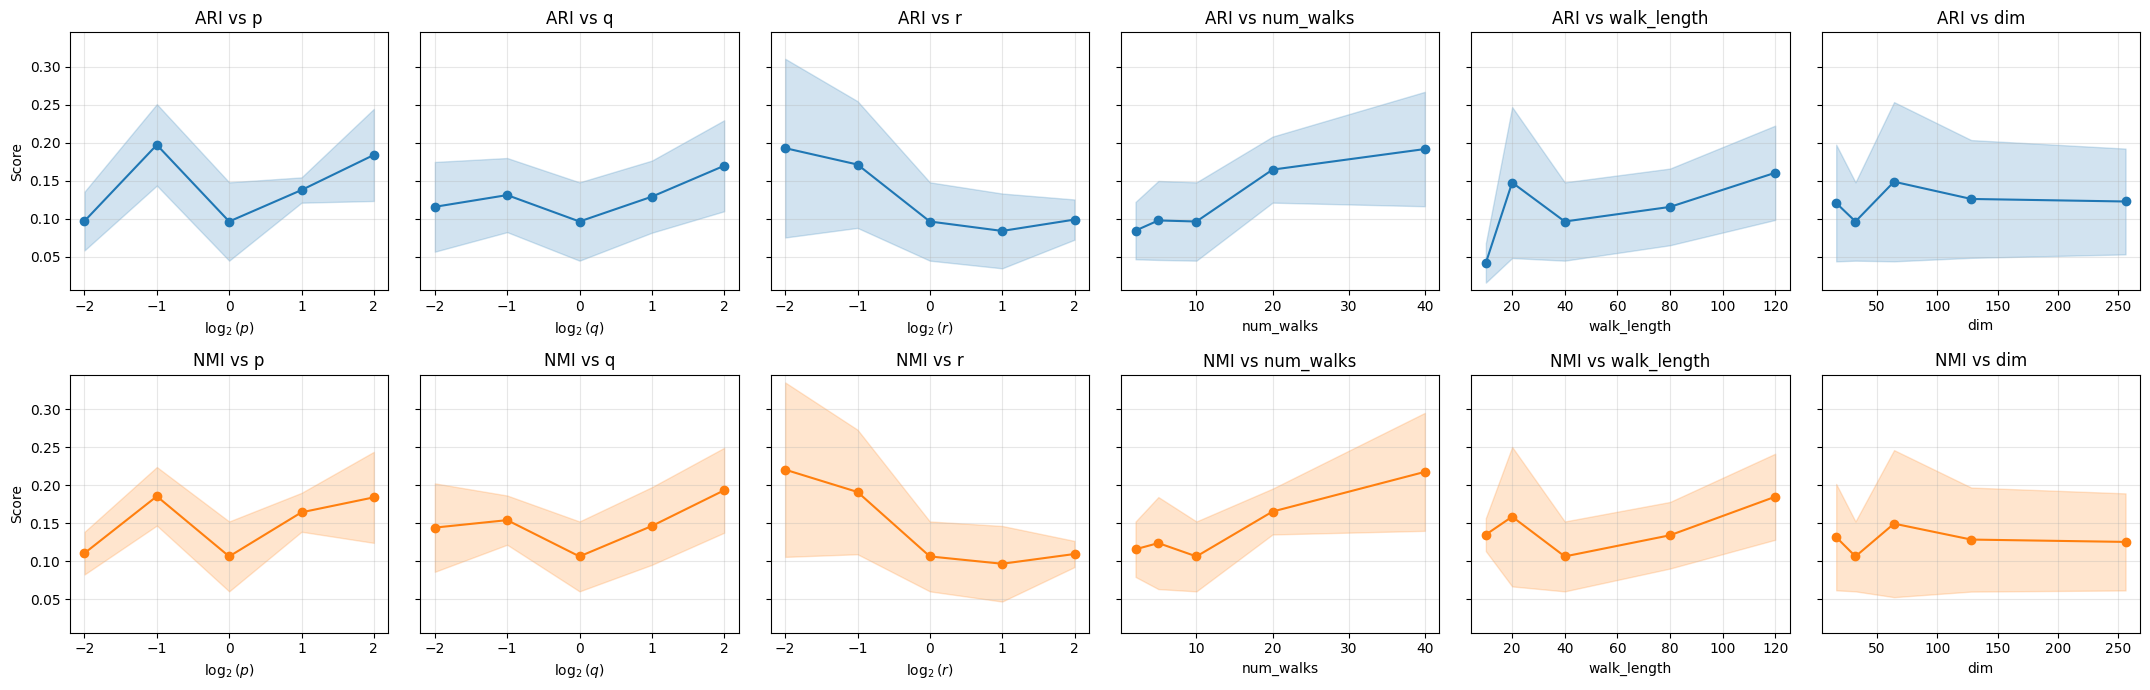

In [13]:
def load_and_tag(csv_path, param_name, use_log2=False):
    df = pd.read_csv(csv_path).copy()
    df["param"] = param_name
    if use_log2:
        df["x"] = np.log2(df[param_name].to_numpy())
    else:
        df["x"] = df[param_name].to_numpy()
    return df

joint = pd.concat([
    load_and_tag(results_dir / "hmrw_p_sweep.csv", "p", use_log2=True),
    load_and_tag(results_dir / "hmrw_q_sweep.csv", "q", use_log2=True),
    load_and_tag(results_dir / "hmrw_r_sweep.csv", "r", use_log2=True),
    load_and_tag(results_dir / "hmrw_num_walks_sweep.csv", "num_walks", use_log2=False),
    load_and_tag(results_dir / "hmrw_walk_length_sweep.csv", "walk_length", use_log2=False),
    load_and_tag(results_dir / "hmrw_dim_sweep.csv", "dim", use_log2=False),
], ignore_index=True)

plot_order = ["p", "q", "r", "num_walks", "walk_length", "dim"]
label_map = {
    "p": r"$\log_2(p)$",
    "q": r"$\log_2(q)$",
    "r": r"$\log_2(r)$",
    "num_walks": "num_walks",
    "walk_length": "walk_length",
    "dim": "dim",
}

ymin = min((joint["ari_mean"] - joint["ari_std"]).min(), (joint["nmi_mean"] - joint["nmi_std"]).min())
ymax = max((joint["ari_mean"] + joint["ari_std"]).max(), (joint["nmi_mean"] + joint["nmi_std"]).max())

fig, axes = plt.subplots(2, len(plot_order), figsize=(3.6 * len(plot_order), 7), sharey=True)

for j, param in enumerate(plot_order):
    sub = joint[joint["param"] == param].sort_values("x")
    x = sub["x"].to_numpy()

    axes[0, j].plot(x, sub["ari_mean"], marker="o", color="tab:blue")
    axes[0, j].fill_between(x, sub["ari_mean"] - sub["ari_std"], sub["ari_mean"] + sub["ari_std"], alpha=0.2, color="tab:blue")
    axes[0, j].set_title(f"ARI vs {param}")
    axes[0, j].set_xlabel(label_map[param])

    axes[1, j].plot(x, sub["nmi_mean"], marker="o", color="tab:orange")
    axes[1, j].fill_between(x, sub["nmi_mean"] - sub["nmi_std"], sub["nmi_mean"] + sub["nmi_std"], alpha=0.2, color="tab:orange")
    axes[1, j].set_title(f"NMI vs {param}")
    axes[1, j].set_xlabel(label_map[param])

axes[0, 0].set_ylabel("Score")
axes[1, 0].set_ylabel("Score")

for ax in axes.ravel():
    ax.set_ylim(max(0.0, ymin - 0.01), min(1.0, ymax + 0.01))
    ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_locator(MultipleLocator(0.05))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

fig.tight_layout()
out_fig = results_dir / "hmrw_joint_sensitivity.png"
fig.savefig(out_fig, dpi=200, bbox_inches="tight")
print(f"Saved figure: {out_fig}")
plt.show()
